In [13]:
import random
from collections import Counter
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from scipy.ndimage import uniform_filter1d
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit

from ml.data_io import iter_signals_and_targets, iter_signals_only
from ml.features import add_epoch_drift, build_feature_df

In [14]:
@dataclass
class Config:  # noqa: D101
    bundle_dir: Path = Path("../data")
    sf: int = 100  # sampling rate
    samples_per_epoch: int = 30 * 100  # 30s epochs
    stage_names: list[str] = field(default_factory=lambda: ["Wake", "N1", "N2", "N3", "REM"])
    bands: dict[str, tuple[float, float]] = field(
        default_factory=lambda: {
            "slow_delta": (0.5, 2),
            "delta": (2, 4),
            "theta": (4, 8),
            "alpha": (8, 12),
            "sigma": (12, 15),
            "beta": (15, 30),
        },
    )
    add_epoch_drift_window: int = 2
    add_epoch_drift_symmetric: bool = True
    # model params
    num_classes: int = 5
    eta: float = 0.05
    max_depth: int = 6
    n_jobs : int = 4
    subsample: float = 0.8
    colsample_bytree: float = 0.8
    num_boost_round: int = 500
    seed: int = 42
    smoothing_window: int = 5
    cv_n_splits: int = 5
    val_frac: float = 0.2
    val_random_state: int = 42

config = Config()

In [15]:
raw_train_data = iter_signals_and_targets(config.bundle_dir, split="train")
raw_test_data = iter_signals_only(config.bundle_dir, split="test")

# Features

In [16]:
df_train = build_feature_df(raw_train_data, with_labels=True, config=config)
df_train = add_epoch_drift(
    df_train,
    window=config.add_epoch_drift_window,
    symmetric=config.add_epoch_drift_symmetric,
)

X_train = df_train.drop(
    columns=[
        "label",
        "identifier",
        "patient_id",
        "epoch_idx",
    ],
)
y_train = df_train["label"]
groups = df_train["patient_id"].to_numpy()

In [17]:
X_train

,mean,std,ptp,slow_delta,delta,theta,alpha,sigma,beta,rel_slow_delta,...,hjorth_mobility,hjorth_complexity,spec_entropy,log_delta_theta,log_alpha_beta,theta_dominance,beta_silence,epoch_drift_prev,epoch_drift_next,epoch_drift_mean
0,-0.002056,0.281659,1.955991,-4.520100,-5.970237,-5.368990,-2.903019,-6.226408,-5.662570,-1.974269,...,0.525593,1.657050,3.710827,-0.601247,2.759551,-2.527367,-0.293580,0.000000,0.006678,0.003339
1,0.000493,0.262859,1.850865,-4.547810,-6.007101,-5.630204,-3.162292,-6.487304,-5.914476,-1.786213,...,0.498394,1.730277,3.624036,-0.376896,2.752184,-2.529749,-0.284272,0.000000,0.005621,0.002811
2,0.000763,0.261666,1.680616,-4.925597,-5.917502,-5.565328,-3.336606,-6.564304,-6.110947,-1.987460,...,0.476152,1.845182,3.490024,-0.352174,2.774341,-2.289244,-0.545619,0.002672,0.008329,0.005500
3,-0.001942,0.241289,1.666237,-5.221362,-6.146073,-5.819474,-3.343122,-6.683003,-6.110944,-2.211694,...,0.497243,1.784376,3.488085,-0.326599,2.767822,-2.537258,-0.291470,0.006678,0.011591,0.009135
4,0.002725,0.240692,1.793912,-4.713387,-5.844990,-5.661986,-3.598101,-6.797852,-6.155221,-1.633371,...,0.489923,1.910061,3.551208,-0.183004,2.557121,-2.138555,-0.493236,0.005621,0.019404,0.012513
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7428,0.000615,0.570573,6.274639,-2.059146,-3.144259,-3.555673,-3.289054,-4.122969,-3.342316,-0.814575,...,0.495431,2.464554,3.962634,0.411414,0.053261,-0.933490,0.213357,0.440484,0.233678,0.337081
7429,0.000891,0.985119,10.758858,-1.192349,-1.859668,-2.987002,-2.994042,-3.925046,-3.032575,-0.726636,...,0.368846,3.321418,3.612344,1.127334,0.038533,-0.667026,-0.045573,0.259940,0.158192,0.209066
7430,0.000443,3.134613,30.283478,1.515543,-0.234421,-1.476548,-1.790474,-2.316442,-1.355371,-0.291877,...,0.274213,5.686316,2.745929,1.242127,-0.435103,-0.620253,0.121177,0.099169,0.113435,0.106302
7431,-0.016104,2.287064,20.639336,0.571515,-0.591914,-1.732648,-2.285462,-2.871787,-1.986277,-0.456876,...,0.294232,4.466963,2.993818,1.140734,-0.299185,-0.301073,-0.253629,0.233678,0.093531,0.163604


# Model 

In [18]:
def train_xgboost(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    config: Config,
):
    # ---- class weights (important for sleep staging) ----
    class_counts = Counter(y_train)
    max_count = max(class_counts.values())
    class_weights = {c: max_count / v for c, v in class_counts.items()}
    sample_weights = y_train.map(class_weights).to_numpy()

    # ---- DMatrix ----
    dtrain = xgb.DMatrix(
        X_train.values,
        label=y_train.values,
        weight=sample_weights,
        feature_names=X_train.columns.tolist(),
    )

    # ---- parameters ----
    params = {
        "objective": "multi:softprob",
        "num_class": config.num_classes,
        "eval_metric": "mlogloss",
        "eta": config.eta,
        "n_jobs": config.n_jobs,
        "max_depth": config.max_depth,
        "subsample": config.subsample,
        "colsample_bytree": config.colsample_bytree,
        "seed": config.seed,
        "tree_method": "hist",
    }

    return xgb.train(
        params=params,
        dtrain=dtrain,
        num_boost_round=config.num_boost_round,
        verbose_eval=False,
    )


def predict_xgboost_patientwise(
    model: xgb.Booster,
    X: pd.DataFrame,
    patient_ids: pd.Series,
    epoch_idx: pd.Series,
    *,
    smoothing_window: int = 5,
):
    dtest = xgb.DMatrix(
        X.values,
        feature_names=X.columns.tolist(),
    )

    probas = model.predict(dtest)
    preds = np.zeros(len(X), dtype=int)

    # operate per patient
    for pid in patient_ids.unique():
        mask = patient_ids == pid
        idx = np.where(mask)[0]

        # sort by epoch
        order = np.argsort(epoch_idx.iloc[idx].values)
        idx_sorted = idx[order]

        p = probas[idx_sorted]

        if smoothing_window > 1:
            p = uniform_filter1d(
                p,
                size=smoothing_window,
                axis=0,
                mode="nearest",
            )

        preds[idx_sorted] = np.argmax(p, axis=1)

    return preds


def cross_validate_xgboost(
    X: pd.DataFrame,
    y: pd.Series,
    groups: np.ndarray,
    df: pd.DataFrame,
    config: Config,
):
    gkf = GroupKFold(n_splits=config.cv_n_splits)

    fold_scores = []

    for fold, (tr_idx, va_idx) in enumerate(gkf.split(X, y, groups)):
        print(f"\n--- Fold {fold + 1}/{config.cv_n_splits} ---")

        X_tr, X_va = X.iloc[tr_idx], X.iloc[va_idx]
        y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]

        model = train_xgboost(X_tr, y_tr, config)

        y_pred = predict_xgboost_patientwise(
            model,
            X_va,
            patient_ids=df.iloc[va_idx]["patient_id"],
            epoch_idx=df.iloc[va_idx]["epoch_idx"],
            smoothing_window=config.smoothing_window,
        )

        f1 = f1_score(y_va, y_pred, average="macro")
        fold_scores.append(f1)

        print(f"Macro-F1: {f1:.4f}")
        print(
            classification_report(
                y_va,
                y_pred,
                target_names=config.stage_names,
                digits=3,
            ),
        )

    print("\n======================")
    print(f"CV Macro-F1: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")
    print(
        classification_report(
            y_va,
            y_pred,
            target_names=config.stage_names,
            digits=3,
        ),
    )
    print("======================")

    return fold_scores, model

In [19]:
gss = GroupShuffleSplit(n_splits=1, test_size=config.val_frac, random_state=config.val_random_state)
tr_idx, va_idx = next(gss.split(X_train, y_train, groups))

X_tr, X_va = X_train.iloc[tr_idx], X_train.iloc[va_idx]
y_tr, y_va = y_train.iloc[tr_idx], y_train.iloc[va_idx]

model = train_xgboost(X_tr, y_tr, config)

y_pred = predict_xgboost_patientwise(
    model,
    X_va,
    patient_ids=df_train.iloc[va_idx]["patient_id"],
    epoch_idx=df_train.iloc[va_idx]["epoch_idx"],
    smoothing_window=config.smoothing_window,
)

f1 = f1_score(y_va, y_pred, average="macro")
print(f"\nTrain/Val Macro-F1: {f1:.4f}")
print(
    classification_report(
        y_va,
        y_pred,
        target_names=config.stage_names,
        digits=3,
    ),
)


Train/Val Macro-F1: 0.7027
              precision    recall  f1-score   support

        Wake      0.884     0.870     0.877       422
          N1      0.143     0.153     0.148        85
          N2      0.823     0.922     0.870       844
          N3      0.907     0.961     0.933       283
         REM      0.871     0.566     0.686       334

    accuracy                          0.823      1968
   macro avg      0.726     0.694     0.703      1968
weighted avg      0.827     0.823     0.818      1968



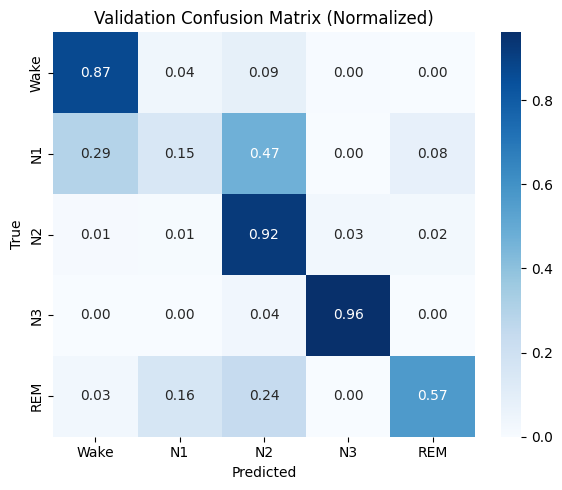

In [20]:
cm = confusion_matrix(y_va, y_pred, normalize="true")

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=config.stage_names,
    yticklabels=config.stage_names,
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Validation Confusion Matrix (Normalized)")
plt.tight_layout()

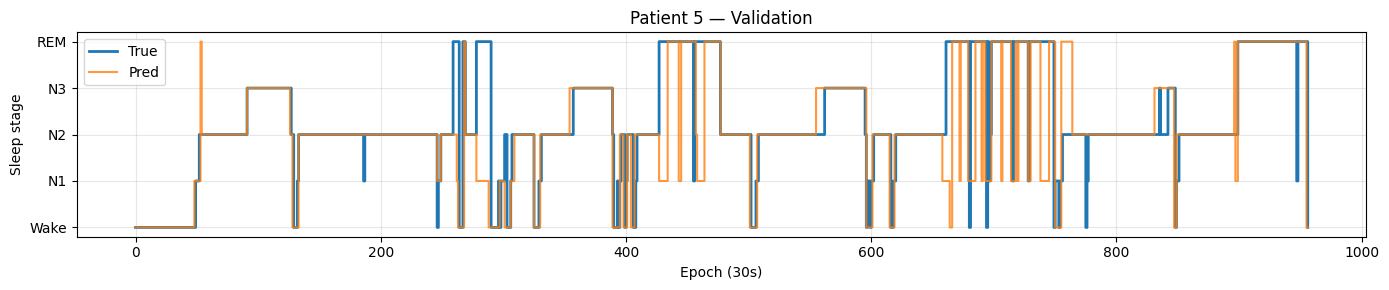

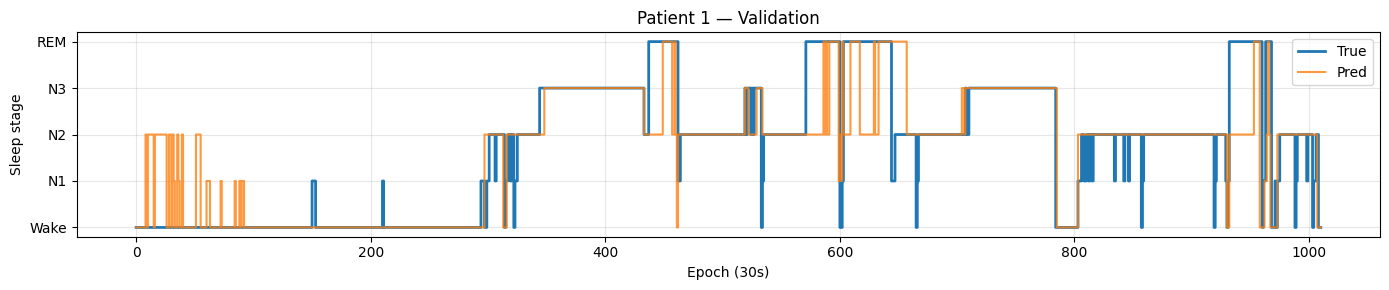

In [21]:
def plot_sleep_timeline_val(df, y_true, y_pred, patient_id, idx_subset):
    mask = (df["patient_id"] == patient_id) & df.index.isin(idx_subset)
    block = df.loc[mask].sort_values("epoch_idx")

    if len(block) == 0:
        return

    true = y_true.loc[block.index].values
    pred = y_pred[np.isin(idx_subset, block.index)]

    plt.figure(figsize=(14, 3))
    plt.plot(true, label="True", drawstyle="steps-post", linewidth=2)
    plt.plot(pred, label="Pred", drawstyle="steps-post", alpha=0.8)
    plt.yticks(
        ticks=[0, 1, 2, 3, 4],
        labels=["Wake", "N1", "N2", "N3", "REM"],
    )
    plt.xlabel("Epoch (30s)")
    plt.ylabel("Sleep stage")
    plt.title(f"Patient {patient_id} — Validation")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

# pick random validation patients
val_patients = df_train.iloc[va_idx]["patient_id"].unique().tolist()
for pid in random.sample(val_patients, k=min(3, len(val_patients))):
    plot_sleep_timeline_val(
        df_train,
        y_va,
        y_pred,
        patient_id=pid,
        idx_subset=va_idx,
    )


# Cross Validation

In [22]:
cv_scores, model = cross_validate_xgboost(
        X_train,
        y_train,
        groups,
        df_train,
        config=config,
    )


--- Fold 1/5 ---
Macro-F1: 0.6264
              precision    recall  f1-score   support

        Wake      0.949     0.842     0.892       330
          N1      0.100     0.022     0.036        46
          N2      0.662     0.949     0.780       332
          N3      0.943     0.949     0.946       175
         REM      0.786     0.344     0.478       128

    accuracy                          0.795      1011
   macro avg      0.688     0.621     0.626      1011
weighted avg      0.794     0.795     0.773      1011


--- Fold 2/5 ---
Macro-F1: 0.5718
              precision    recall  f1-score   support

        Wake      0.852     0.495     0.626        93
          N1      0.459     0.270     0.340        63
          N2      0.575     0.937     0.713       395
          N3      0.983     0.538     0.695       212
         REM      0.636     0.392     0.485       227

    accuracy                          0.642       990
   macro avg      0.701     0.526     0.572       990
weighte

# Generate Submission 

In [23]:
df_test  = build_feature_df(raw_test_data,  with_labels=False, config=config)
df_test  = add_epoch_drift(df_test,  window=2)

X_test = df_test.drop(columns=[
    "identifier", "patient_id", "epoch_idx",
])

In [24]:
# Predict on test
y_test_pred = predict_xgboost_patientwise(
    model,
    X_test,
    patient_ids=df_test["patient_id"],
    epoch_idx=df_test["epoch_idx"],
    smoothing_window=5,
)

In [25]:
submissions = pd.DataFrame({
    "identifier": df_test["identifier"],
    "label": y_test_pred,
})
submissions.to_csv("../submission.csv", index=False)